<a href="https://colab.research.google.com/github/rafiebazine/rag-image-captioning/blob/hadil/phase_02_preprocessing/05_quality_control.ipyn" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
caption mismatches (raw vs original): 0
overlaps: {'kb_10k&val_100': 0, 'kb_10k&test_100': 0, 'kb_10k&test_1000': 0, 'val_100&test_100': 0, 'val_100&test_1000': 0, 'test_100&test_1000': 0}
identical caption strings between KB and val/test (info only): 53


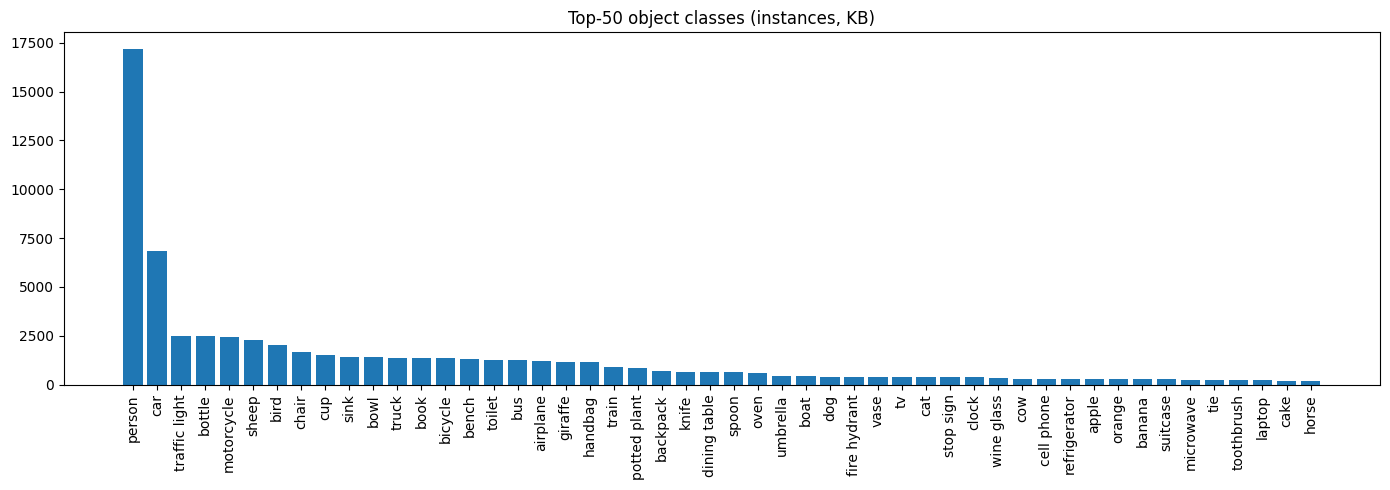

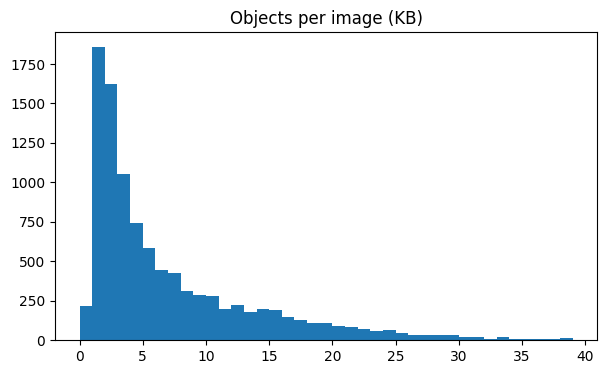

avg objects/image: 6.71 | median: 4.0


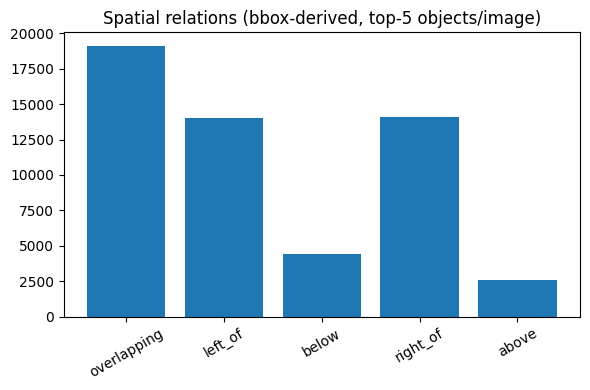

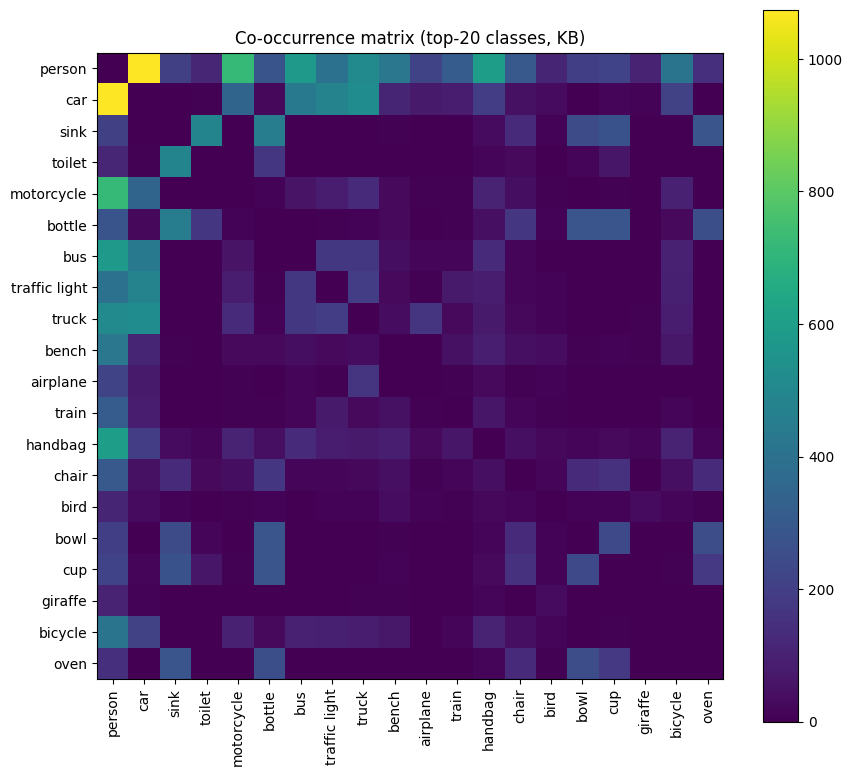

captions: 50000 | avg length: 10.41 | vocab size: 9364


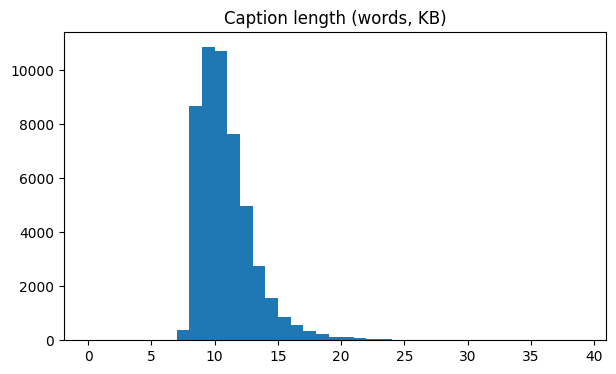

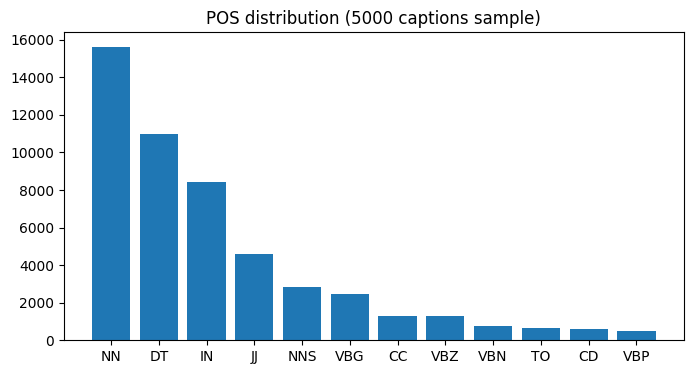

retrieval pipeline OK: no eval image/caption ever retrieved
{
 "caption_mismatches": 0,
 "overlaps": {
  "kb_10k&val_100": 0,
  "kb_10k&test_100": 0,
  "kb_10k&test_1000": 0,
  "val_100&test_100": 0,
  "val_100&test_1000": 0,
  "test_100&test_1000": 0
 },
 "identical_caption_strings_kb_vs_eval": 53,
 "retrieval_validation": "OK",
 "avg_objects_per_image": 6.71,
 "images_without_objects": 219,
 "avg_caption_length": 10.41,
 "vocab_size": 9364,
 "spatial_relations": {
  "overlapping": 19104,
  "left_of": 14037,
  "below": 4428,
  "right_of": 14118,
  "above": 2566
 },
 "top10_classes": [
  [
   "person",
   17177
  ],
  [
   "car",
   6820
  ],
  [
   "traffic light",
   2494
  ],
  [
   "bottle",
   2468
  ],
  [
   "motorcycle",
   2430
  ],
  [
   "sheep",
   2302
  ],
  [
   "bird",
   2047
  ],
  [
   "chair",
   1659
  ],
  [
   "cup",
   1519
  ],
  [
   "sink",
   1432
  ]
 ]
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
!pip -q install faiss-cpu
import os, json, time, numpy as np, faiss, itertools
from collections import Counter
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount("/content/drive")

REPO = "/content/rag-image-captioning"
if not os.path.exists(REPO):
    os.system(f"git clone -q https://github.com/rafiebazine/rag-image-captioning.git {REPO}")
    os.system(f"cd {REPO} && git checkout -q hadil")

DRIVE_DIR = "/content/drive/MyDrive/rag_embeddings"
PROC = f"{REPO}/phase_02_preprocessing/processed"
SPLIT = f"{REPO}/phase_01_data_exploration/splitted_data_set"
QC = f"{PROC}/qc"; os.makedirs(QC, exist_ok=True)
names = ["kb_10k", "val_100", "test_100", "test_1000"]
report = {}

# ---------- 1) Audit: embeddings, IDs, caption integrity ----------
ids = {n: json.load(open(f"{DRIVE_DIR}/{n}_image_ids.json")) for n in names}
emb = {n: np.load(f"{DRIVE_DIR}/{n}_image_emb.npy") for n in names}
txt = np.load(f"{DRIVE_DIR}/kb_text_emb.npy")
owners = json.load(open(f"{DRIVE_DIR}/kb_text_owners.json"))
for n in names:
    assert emb[n].shape == (len(ids[n]), 512) and not np.isnan(emb[n]).any()
    assert len(set(ids[n])) == len(ids[n]), f"duplicate IDs in {n}"
assert txt.shape == (50000, 512) and not np.isnan(txt).any()

orig = json.load(open(f"{SPLIT}/kb_10k.json"))        #  (Rafie)
clean = json.load(open(f"{PROC}/kb_10k_clean.json"))
mism = sum(o["captions"] != c["captions_raw"] for o, c in zip(orig, clean))
assert [o["image_id"] for o in orig] == [c["image_id"] for c in clean]
print("caption mismatches (raw vs original):", mism)
report["caption_mismatches"] = mism

# ---------- 2) Leakage audit ----------
sets = {n: set(ids[n]) for n in names}
pairs = list(itertools.combinations(names, 2))
overlaps = {f"{a}&{b}": len(sets[a] & sets[b]) for a, b in pairs}
print("overlaps:", overlaps)
assert overlaps["kb_10k&val_100"] == overlaps["kb_10k&test_100"] == overlaps["kb_10k&test_1000"] == 0
test_caps = {c for n in ["val_100", "test_100", "test_1000"] for x in json.load(open(f"{PROC}/{n}_clean.json")) for c in x["captions_clean"]}
kb_caps = {c for x in clean for c in x["captions_clean"]}
exact_dups = len(test_caps & kb_caps)
print("identical caption strings between KB and val/test (info only):", exact_dups)
report.update(overlaps=overlaps, identical_caption_strings_kb_vs_eval=exact_dups)

# ---------- 3) Statistics: objects, complexity, relations, co-occurrence ----------
meta = json.load(open(f"{PROC}/metadata_kb_10k.json"))
cat_img = Counter(c for m in meta for c in m["object_counts"])            # images containing class
cat_inst = Counter()
for m in meta:
    for c, k in m["object_counts"].items(): cat_inst[c] += k
top50 = cat_inst.most_common(50)
plt.figure(figsize=(14, 5)); plt.bar([c for c, _ in top50], [v for _, v in top50])
plt.xticks(rotation=90); plt.title("Top-50 object classes (instances, KB)"); plt.tight_layout()
plt.savefig(f"{QC}/top50_objects.png", dpi=150); plt.show()

n_obj = [m["num_objects"] for m in meta]
plt.figure(figsize=(7, 4)); plt.hist(n_obj, bins=range(0, 40)); plt.title("Objects per image (KB)")
plt.savefig(f"{QC}/objects_per_image.png", dpi=150); plt.show()
print("avg objects/image:", round(np.mean(n_obj), 2), "| median:", np.median(n_obj))

def relation(a, b):
    ax, ay, aw, ah = a["bbox"]; bx, by, bw, bh = b["bbox"]
    if ax < bx + bw and bx < ax + aw and ay < by + bh and by < ay + ah: return "overlapping"
    dx, dy = (ax + aw/2) - (bx + bw/2), (ay + ah/2) - (by + bh/2)
    return ("left_of" if dx < 0 else "right_of") if abs(dx) > abs(dy) else ("above" if dy < 0 else "below")
rel = Counter()
for m in meta:
    objs = sorted(m["objects"], key=lambda o: -o["area"])[:5]
    for a, b in itertools.combinations(objs, 2): rel[relation(a, b)] += 1
plt.figure(figsize=(6, 4)); plt.bar(rel.keys(), rel.values()); plt.title("Spatial relations (bbox-derived, top-5 objects/image)")
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig(f"{QC}/spatial_relations.png", dpi=150); plt.show()

top20 = [c for c, _ in cat_img.most_common(20)]
co = np.zeros((20, 20), int)
for m in meta:
    present = [c for c in top20 if c in m["object_counts"]]
    for a, b in itertools.permutations(present, 2): co[top20.index(a), top20.index(b)] += 1
plt.figure(figsize=(9, 8)); plt.imshow(co, cmap="viridis"); plt.colorbar()
plt.xticks(range(20), top20, rotation=90); plt.yticks(range(20), top20)
plt.title("Co-occurrence matrix (top-20 classes, KB)"); plt.tight_layout()
plt.savefig(f"{QC}/cooccurrence.png", dpi=150); plt.show()

# ---------- 4) Caption statistics: length, vocabulary, POS ----------
caps = [c for x in clean for c in x["captions_clean"]]
lens = [len(c.split()) for c in caps]
vocab = Counter(w for c in caps for w in c.split())
print("captions:", len(caps), "| avg length:", round(np.mean(lens), 2), "| vocab size:", len(vocab))
plt.figure(figsize=(7, 4)); plt.hist(lens, bins=range(0, 40)); plt.title("Caption length (words, KB)")
plt.savefig(f"{QC}/caption_length.png", dpi=150); plt.show()

import nltk
for r in ["averaged_perceptron_tagger_eng", "averaged_perceptron_tagger"]: nltk.download(r, quiet=True)
sample = np.random.default_rng(42).choice(len(caps), 5000, replace=False)
pos = Counter(t for i in sample for _, t in nltk.pos_tag(caps[i].split()))
top_pos = pos.most_common(12)
plt.figure(figsize=(8, 4)); plt.bar([p for p, _ in top_pos], [v for _, v in top_pos]); plt.title("POS distribution (5000 captions sample)")
plt.savefig(f"{QC}/pos_distribution.png", dpi=150); plt.show()

# ---------- 5) End-to-end retrieval validation (frozen release) ----------
index_img = faiss.read_index(f"{DRIVE_DIR}/faiss/kb_image.index")
index_txt = faiss.read_index(f"{DRIVE_DIR}/faiss/kb_text.index")
records = json.load(open(f"{DRIVE_DIR}/kb_records.json"))
for n in ["val_100", "test_100", "test_1000"]:
    s, i = index_img.search(emb[n], 10)
    retrieved = {ids["kb_10k"][j] for row in i for j in row}
    assert not (retrieved & sets[n]), f"{n}: an eval image was retrieved from KB (leak)"
    _, it = index_txt.search(emb[n], 10)
    assert all(owners[j][0] not in sets[n] for row in it for j in row)
print("retrieval pipeline OK: no eval image/caption ever retrieved")
report["retrieval_validation"] = "OK"

report.update(avg_objects_per_image=round(float(np.mean(n_obj)), 2), images_without_objects=int(sum(k == 0 for k in n_obj)),
              avg_caption_length=round(float(np.mean(lens)), 2), vocab_size=len(vocab),
              spatial_relations=dict(rel), top10_classes=cat_inst.most_common(10))
json.dump(report, open(f"{PROC}/qc_report.json", "w"), indent=1)
print(json.dumps(report, indent=1))

!cd {PROC} && zip -qr qc_outputs.zip qc qc_report.json
from google.colab import files; files.download(f"{PROC}/qc_outputs.zip")